In [42]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split,RandomizedSearchCV
from sklearn.preprocessing import StandardScaler,FunctionTransformer
from sklearn.metrics import confusion_matrix,f1_score,accuracy_score,precision_score,recall_score
import joblib

In [43]:
rfm = pd.read_csv("../data/clients_rfm.csv")

In [44]:
rfm["Cluster"].value_counts()

Cluster
Bronze    1890
Silver    1699
Gold       749
Name: count, dtype: int64

<Axes: xlabel='Cluster'>

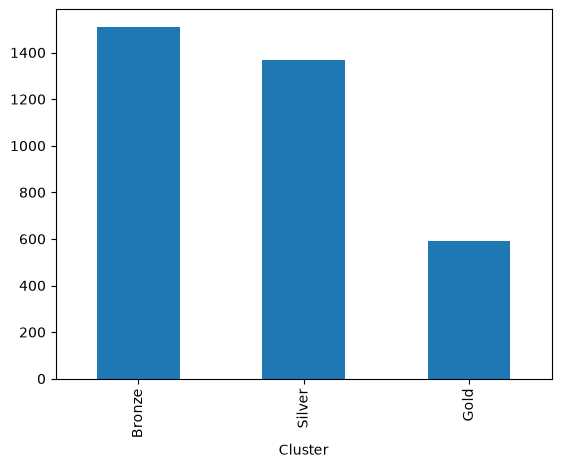

In [45]:
features = ["Recency","Frequency","Monetary"]
X_train, X_test, y_train, y_test = train_test_split(rfm[features],rfm["Cluster"],test_size=0.2,random_state=42)
y_train.value_counts().plot(kind="bar")


In [46]:
preprocessor = ColumnTransformer(
    transformers=[
    ("standarization",Pipeline(
        steps=[
            ("log1p",FunctionTransformer(np.log1p)),
            ("std",StandardScaler())
    ]),features)],
    n_jobs=-1,
    remainder="drop"
    )


In [47]:
model = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",RandomForestClassifier())
    ]
)

In [48]:

params = {
    "model__n_estimators": [200, 500, 1000],
    "model__max_depth": [None, 5, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__max_features": ["sqrt", "log2", 0.5, 1.0],
    "model__class_weight": [None, "balanced", "balanced_subsample"]
}
search = RandomizedSearchCV(
    estimator=model,
    param_distributions = params,
    n_iter=20,
    cv=5,
    scoring="f1_macro",
    random_state=42,
    n_jobs=-1
)
search.fit(X_train, y_train)

print(search.best_estimator_)
print(search.best_score_)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(n_jobs=-1,
                                   transformers=[('standarization',
                                                  Pipeline(steps=[('log1p',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('std',
                                                                   StandardScaler())]),
                                                  ['Recency', 'Frequency',
                                                   'Monetary'])])),
                ('model',
                 RandomForestClassifier(max_depth=30, n_estimators=500))])
0.9732367688436769


selon les recherches effectuées par randomizedsearchcv on trouve que {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 30, 'class_weight': None} sont les meilleurs valeurs identifié en se basant sur le metric accuracy

In [54]:
model = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",RandomForestClassifier(
                        n_estimators=500,
                        min_samples_split=2,
                        min_samples_leaf=1,
                        max_features="sqrt",
                        max_depth=30,
                        class_weight=None
                    ))
    ]
)
model.fit(X=X_train,y=y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred,average="weighted")
recall = recall_score(y_test, y_pred,average="weighted")
f1 = f1_score(y_test, y_pred,average="weighted")
cm = confusion_matrix(y_test, y_pred, labels=["Gold","Silver","Bronze"])

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)
print("\nConfusion Matrix:")
print(cm)

importance = pd.DataFrame({
    'Variable': ['Recence', 'Frequence', 'Montant'],
    'Importance': model.named_steps["model"].feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)


Accuracy : 0.9873271889400922
Precision: 0.9873721044868871
Recall   : 0.9873271889400922
F1-score : 0.9873371988294753

Confusion Matrix:
[[153   3   0]
 [  2 329   2]
 [  0   4 375]]
    Variable  Importance
2    Montant    0.357014
1  Frequence    0.330344
0    Recence    0.312642


In [55]:
joblib.dump(model,"../artifacts/classification_model.pkl")

['../artifacts/classification_model.pkl']